In [ ]:
!pip install "jax[cuda13]==0.10.2"
!pip install "flax==0.12.8"
!pip install abmax
!pip install kozax
!pip install optax
!pip install --no-deps gymnax==0.0.9

In [ ]:
# Prepare the tutorial workspace

from pathlib import Path
from urllib.request import urlretrieve
import os

# This will be our working folder in Colab
ROOT = Path("/content/SAB_tut")
ROOT.mkdir(parents=True, exist_ok=True)

# Location of render.py on GitHub
RENDER_URL = (
    "https://raw.githubusercontent.com/"
    "sab-gp-cas-tutorial/website/main/tutorial/render.py"
)

# Download render.py
urlretrieve(RENDER_URL, ROOT / "render.py")

# Create the folder used for arrays and videos
(ROOT / "render_data").mkdir(exist_ok=True)

# Make SAB_tut the current working directory
os.chdir(ROOT)

print("Tutorial workspace created:")
print(ROOT)

print("\nAvailable files:")
for path in ROOT.iterdir():
    print(" -", path.name)

# Evolutionary Discovery of Residential Relocation Rules

This tutorial implements a Schelling-style residential mobility model in ABMax and uses Kozax genetic programming to discover agent utility functions.

The model is inspired by Gunaratne et al. (2023), *Generating Mixed Patterns of Residential Segregation: An Evolutionary Approach*. Rather than fixing a relocation rule in advance, we give agents interpretable neighborhood features and evolve rules that produce a target macro-pattern: the coexistence of blue-homogeneous, green-homogeneous, and mixed neighborhoods.

Our implementation includes several adaptations:

- A toroidal grid with Moore neighborhoods (the eight surrounding cells).
- Synchronous relocation using maximum-weight matching, so no two agents choose the same vacant cell in a tick.
- Five candidate utility features: recent movement history, same-color neighbors, nearby vacancies, distance, and neighbor age.

In [ ]:
# Choose the execution backend.
# For local CPU execution, set `backend = "cpu"` and optionally configure
# XLA_FLAGS before importing JAX to expose multiple host devices.
backend = "gpu"

from pathlib import Path

import jax
import jax.numpy as jnp
import jax.random as random
import matplotlib.pyplot as plt
import optax
from flax import struct

from abmax.contexts.traffic.algorithms import *
from abmax.functions import *
from abmax.structs import *

from kozax.fitness_functions.base_fitness_function import BaseFitnessFunction
from kozax.fitness_functions.SR_fitness_function import SymbolicRegressionFitnessFunction
from kozax.genetic_programming import GeneticProgramming

jax.config.update("jax_compilation_cache_dir", str(CACHE))
jax.config.update("jax_persistent_cache_min_compile_time_secs", 0)
jax.config.update("jax_persistent_cache_min_entry_size_bytes", -1)

print("JAX:", jax.__version__)
print("Devices:", jax.devices())

These device(s) are detected: [CudaDevice(id=0)]
JAX: 0.10.2
Devices: [CudaDevice(id=0)]


# **ABMax tutorial**
In this tutorial we will first develop a basic schelling model using ABMax then run it with different agent utility assignment function.


In [ ]:
KEY = jax.random.PRNGKey(0)

# Simulation configuration
GRID_SIZE = 15
EPISODE_LENGTH = 150
MOVE_WINDOW = 10
VACANCY_RATE = 0.10 # fraction of cells empty

# Evolution configuration
NUM_SCENARIOS = 2
FITNESS_WINDOW = 50
POP_SIZE = 80
NUM_GENERATIONS = 25

NUM_AGENTS = GRID_SIZE**2
NUM_INACTIVE_AGENTS = int(NUM_AGENTS * VACANCY_RATE)
NUM_ACTIVE_AGENTS = NUM_AGENTS - NUM_INACTIVE_AGENTS


## Experiment Configuration

The city is a $15 \times 15$ toroidal grid: crossing an edge returns an agent to the opposite side. Each episode begins with 10% vacant cells, leaving agents with possible relocation destinations.

A candidate utility rule is evaluated in multiple stochastic scenarios. We score the final portion of each episode (`FITNESS_WINDOW`) rather than a single tick, which favors patterns that persist instead of brief transients.

The small grid and evolutionary settings are tutorial-friendly defaults. Increase `GRID_SIZE`, `EPISODE_LENGTH`, `NUM_SCENARIOS`, population size, and generations for more robust experiments, at a higher computational cost.

## Agent State and Local Features

Each grid cell is represented by an ABMax `Agent`. An active agent occupies the cell and has one of two group labels: blue (`1`) or green (`-1`). An inactive agent represents a vacant cell and has label `0`.

Each agent stores fixed spatial information and dynamic simulation state:

- **Fixed parameters:** grid coordinates and the IDs of the eight cells in its Moore neighborhood.
- **Neighborhood features:** same-group share, vacancy share, and normalized mean neighbor age.
- **Mobility feature:** a rolling history of the previous `MOVE_WINDOW` ticks.
- **Candidate features:** same-group share and toroidal distance for every vacant cell.
- **Utilities:** the current-location utility and one utility per vacant candidate cell.

The model uses the same feature vector for the current location and each candidate location:

$$
[f_{\mathrm{move}}, f_{\mathrm{color}}, f_{\mathrm{empty}}, f_{\mathrm{dist}}, f_{\mathrm{age}}].
$$

`f_move` is intentionally location-dependent. At the current home it measures recent *stability* ($1 -$ recent move frequency); at a candidate it measures recent *movement tendency*. This distinction lets an evolved rule express different preferences for staying and relocating.

In [ ]:
@struct.dataclass
class SchellingAgent(Agent):
    @staticmethod
    def create_agent(type, params, id, active_state, key):

        grid_X, grid_Y = jnp.array([0]), jnp.array([0])
        ids_around_me = jnp.array([0, 0, 0, 0, 0, 0, 0, 0]) # ids of the agents around this agent (8 neighbors), can be initialized once, no need to update it every step, since the ids of the agents around this agent will not change, only their states will change

        param_content = {'X': grid_X, 'Y': grid_Y, 'ids_around_me': ids_around_me}
        agent_params = Params(content=param_content)

        color = jnp.array([0.0]) # color of the agent, 1.0 for blue, -1.0 for green, 0.0 for inactive

        num_blues = jnp.array([0]) # number of blue agents around the agent
        num_greens = jnp.array([0]) # number of green agents around

        f_color_self = jnp.array([0.0]) # proportion of neighbors around the agent with the same color as the agent
        f_color_candidates = jnp.zeros(NUM_INACTIVE_AGENTS) # proportion of neighbors around the candidate cells with the same color as the agent

        f_empty_self = jnp.array([0.0]) # proportion of empty neighbors around the agent
        f_age_self = jnp.array([0.0]) # mean age of neighbors around the agent

        f_dist_candidates = jnp.zeros(NUM_INACTIVE_AGENTS) # array of distances to free cells

        f_move_self = jnp.array([0.0]) # 1 - agent's mean moving frequency (a moving average of the last 10 moves)
        move_history_self = jnp.ones((MOVE_WINDOW,)) * -1.0 # agent's moving history (1 if the agent moved, 0 otherwise), initialized to -1.0 to indicate that the agent has not moved yet
        move_flag = jnp.array([0.0]) # Has the agent recently moved? 1 is set externally and the 0 is default value,

        utility_self = jnp.array([0.0]) # agent's utility, initialized to 0.0
        utility_candidates = jnp.zeros(NUM_INACTIVE_AGENTS) # array of utilities for the candidate cells, initialized to 0.0

        state_content = {'f_color_self': f_color_self, 'f_color_candidates': f_color_candidates,
                         'f_empty_self': f_empty_self, 'f_age_self': f_age_self,
                         'f_dist_candidates': f_dist_candidates, 'f_move_self': f_move_self,
                         'move_history_self': move_history_self, 'move_flag': move_flag,
                         'color': color, 'num_blues': num_blues, 'num_greens': num_greens,
                         'utility_self': utility_self, 'utility_candidates': utility_candidates}

        agent_state = State(content=state_content)

        return SchellingAgent(id=id, active_state=active_state, age = 0.0, agent_type=type,
                              params=agent_params, state=agent_state, policy=None, key=key)

    @staticmethod
    def set_neighbor_ids(agent) -> Agent:
        # get the ids of the agents around this agent (8 neighbors)
        # get the coordinates of the agent
        agent_id = agent.id
        agent_X, agent_Y = jit_cell_id_to_XY(jnp.array([agent_id]), jnp.array([GRID_SIZE]), jnp.array([GRID_SIZE])) # get the grid coordinates
        cells_around_me_XY = jnp.array([agent_X, agent_Y]) + jnp.array([[[-1], [-1]], [[0], [-1]], [[1], [-1]], [[-1], [0]], [[1], [0]], [[-1], [1]], [[0], [1]], [[1], [1]]])
        cells_around_me_XY = jnp.mod(cells_around_me_XY, jnp.array([[GRID_SIZE], [GRID_SIZE]])) # wrap the coordinates around the grid size

        ids_around_me = jax.vmap(jit_XY_to_cell_id, in_axes=(0, 0, None, None))(cells_around_me_XY[:, 0], cells_around_me_XY[:, 1], jnp.array([GRID_SIZE]), jnp.array([GRID_SIZE])) # get the ids of the agents around this agent (8 neighbors)
        ids_around_me = ids_around_me.reshape(-1) # flatten the array
        agent_params_new = agent.params.replace(content={'X': agent_X, 'Y': agent_Y, 'ids_around_me': ids_around_me})

        return agent.replace(params=agent_params_new)

    @staticmethod
    def set_utility(agent, set_params) -> Agent:
        self_utility = set_params.content['utility_self']
        candidates_utility = set_params.content['utility_candidates']
        agent_state_new = agent.state.replace(content={**agent.state.content, 'utility_self': self_utility * agent.active_state, 'utility_candidates': candidates_utility * agent.active_state})
        return agent.replace(state=agent_state_new)


    @staticmethod
    def step_neighborhood(agent: Agent, input: Signal, step_params: Params) -> Agent: # get neighborhhod info
        agents = step_params.content['agents']
        ids_around_me = agent.params.content['ids_around_me'] # ids of the agents around this agent (8 neighbors)
        color = agent.state.content['color']

        colors_around_me = agents.state.content['color'][ids_around_me].reshape(-1) # get the colors of the agents around this agent (8 neighbors)
        age_around_me = agents.age[ids_around_me].reshape(-1) # get the ages of the agents around this agent (8 neighbors)

        #color and emptiness calculations
        num_blues = jnp.sum(colors_around_me == 1.0).reshape(1) # number of blue neighbors
        num_greens = jnp.sum(colors_around_me == -1.0).reshape(1) # number of green neighbors
        num_active_neighbors = num_blues[0] + num_greens[0]
        num_inactive_neighbors = 8 - num_active_neighbors
        num_active_neighbors_div_safe = jnp.maximum(num_active_neighbors, 1.0) # avoid division by zero

        f_color_self = jax.lax.cond(color[0]> 0.0, lambda _: num_blues / num_active_neighbors_div_safe, lambda _: num_greens / num_active_neighbors_div_safe, None) # proportion of neighbors with the same color
        f_color_self = f_color_self * agent.active_state
        f_empty_self = jnp.array([num_inactive_neighbors / 8.0]) # proportion of empty neighbors

        # age calculations
        max_age_div_safe = jnp.maximum(step_params.content['max_age'], 1.0) # maximum age of the agents in the environment
        f_age_self = jnp.sum(age_around_me).reshape(1) / (num_active_neighbors_div_safe * max_age_div_safe) # mean age of neighbors


        # move is updated to one in the add_agent function, IMP!!!
        # move history calculations
        move_history_self = jnp.roll(agent.state.content['move_history_self'], shift=-1, axis=-1) # shift the move history to the left
        move_history_self = move_history_self.at[-1].set(agent.state.content['move_flag'][0]) # set
        num_moves = jnp.sum(jnp.where(move_history_self != -1.0, 1.0,0.0)) # number of moves in the last 10 steps
        f_move_self = 1.0 - (jnp.sum(move_history_self == 1.0) / num_moves) # 1- agent's mean moving frequency (a moving average of the last 10 moves)
        f_move_self = f_move_self.reshape(1)
        move_flag = jnp.array([0.0])



        agent_state_new = agent.state.replace(content={**agent.state.content, 'num_blues': num_blues, 'num_greens': num_greens,
                                                       'f_color_self': f_color_self, 'f_age_self': f_age_self,'f_move_self': f_move_self,
                                                       'f_empty_self': f_empty_self, 'move_history_self': move_history_self,
                                                       'move_flag': move_flag})

        return agent.replace(state=agent_state_new, age = agent.age + agent.active_state)

    @staticmethod
    def step_candidates(agent: Agent, input: Signal, step_params: Params) -> Agent: # set self info
        agents = step_params.content['agents']
        candidate_Xs = step_params.content['candidate_Xs'].reshape(-1) # x coordinates of the free cells in the environment
        candidate_Ys = step_params.content['candidate_Ys'].reshape(-1) # y coordinates of the free cells in the environment
        candidate_ids = step_params.content['candidate_ids'] # must have shape (NUM_INACTIVE_AGENTS, 1)

        color = agent.state.content['color']

        num_blues_candidates = agents.state.content['num_blues'][candidate_ids].reshape(-1)
        num_greens_candidates = agents.state.content['num_greens'][candidate_ids].reshape(-1)

        num_active_neighbors_candidates = num_blues_candidates + num_greens_candidates
        num_active_neighbors_candidates_div_safe = jnp.maximum(num_active_neighbors_candidates, 1.0) # avoid division by zero

        f_color_candidates_new = jax.lax.cond(color[0] > 0.0, lambda _: num_blues_candidates / num_active_neighbors_candidates_div_safe,
                                             lambda _: num_greens_candidates / num_active_neighbors_candidates_div_safe, None) # proportion of neighbors with the same color
        f_color_candidates_new = f_color_candidates_new * agent.active_state

        candidate_dist_xs = jnp.minimum(jnp.abs(candidate_Xs - agent.params.content['X'][0]), GRID_SIZE - jnp.abs(candidate_Xs - agent.params.content['X'][0]))
        candidate_dist_ys = jnp.minimum(jnp.abs(candidate_Ys - agent.params.content['Y'][0]), GRID_SIZE - jnp.abs(candidate_Ys - agent.params.content['Y'][0]))

        max_wrapped_delta = GRID_SIZE // 2
        max_toroidal_distance = jnp.sqrt(2.0) * max_wrapped_delta

        f_dist_candidates_new = (jnp.sqrt(candidate_dist_xs ** 2 + candidate_dist_ys ** 2)/ max_toroidal_distance)

        agent_state_new = agent.state.replace(content={**agent.state.content, 'f_color_candidates': f_color_candidates_new, 'f_dist_candidates': f_dist_candidates_new})
        return agent.replace(state=agent_state_new) # increment age only if the agent is active



    @staticmethod
    def reset_agent(agent: Agent, reset_params: Params) -> Agent: # code to reset agent in the beginning of each epoch
        key, subkey = random.split(agent.key)
        color = random.choice(subkey, jnp.array([-1.0, 1.0]), p=jnp.array([0.5, 0.5]), shape=(1,)) # assign a random color to the agent

        move_history_self = jnp.ones((MOVE_WINDOW,)) * -1.0 # agent's moving history (1 if the agent moved, 0 otherwise), initialized to -1.0 to indicate that the agent has not moved yet
        move_flag = jnp.array([0.0])

        utility_self = jnp.array([0.0]) # agent's utility, initialized to 0.0
        utility_candidates = jnp.zeros(NUM_INACTIVE_AGENTS) # array of utilities for the candidate cells, initialized to 0.0

        agent_state_new = agent.state.replace(content={**agent.state.content, 'color': color, 'move_history_self': move_history_self, 'move_flag': move_flag, 'utility_self': utility_self, 'utility_candidates': utility_candidates})
        return agent.replace(state=agent_state_new, active_state= 1 , age = 0.0, key=key) # reset age to 0.0 and update the key

    @staticmethod
    def activate_agent(agent, parent_id, step_params) -> Agent:
        agents = step_params.content['agents']
        agent_to_move = jax.tree_util.tree_map(lambda x: x[parent_id], agents)

        move_flag = jnp.array([1.0]) # set move_flag to 1 to indicate that the agent has moved
        move_history = agent_to_move.state.content['move_history_self'] # copy the move history from the agent to move
        color = agent_to_move.state.content['color'] # copy the color from the agent to

        state_content = {**agent.state.content, 'color': color, 'move_history_self': move_history, 'move_flag': move_flag}
        agent_state_new = agent.state.replace(content=state_content)

        return agent.replace(active_state=1, age=0.0, state=agent_state_new) # reset age to 0.0 when the agent is activated


    @staticmethod
    def inactivate_agent(agent: Agent, inactivate_params: Params) -> Agent: # this is equivalent to removing agents, in the beginning we do it for random agents but late we do it for all.
        agent_state_new = agent.state.replace(content={**agent.state.content, 'color': jnp.array([0.0]), 'utility_self': jnp.array([0.0])})
        return agent.replace(state=agent_state_new, active_state= 0 , age = 0.0)

### `SchellingAgent` Methods

#### `create_agent(type, params, id, active_state, key)`

Creates one agent record for each grid cell. At this stage every cell has placeholder coordinates and neighbor IDs; `set_neighbor_ids` fills them in once the grid has been created.

The method initializes:

- Static parameters: coordinates (`X`, `Y`) and the eight neighboring cell IDs.
- Group label (`color`): initially `0`, meaning vacant.
- Local and candidate feature arrays.
- A relocation-history buffer filled with `-1`, which denotes ticks before the agent has recorded a move outcome.
- Current and candidate utility values.

ABMax later stacks these individual records into a vectorized collection of agents.

#### `set_neighbor_ids(agent)`

Computes and caches spatial information that never changes during an episode:

1. Converts the cell ID into $(x, y)$ grid coordinates.
2. Adds the eight Moore-neighborhood offsets.
3. Wraps coordinates with modulo arithmetic, making the grid toroidal.
4. Converts the wrapped neighbor coordinates back to cell IDs.
5. Stores the coordinates and neighbor IDs in `agent.params`.

Caching these IDs avoids recomputing the neighborhood topology at every simulation tick.

#### `set_utility(agent, set_params)`

Writes precomputed utility values into one agent's state.

The utility calculation is performed for the entire agent population elsewhere because it is naturally vectorized. This small helper receives one row of those results and stores:

- `utility_self`: utility of remaining in the current cell.
- `utility_candidates`: utilities of moving to each vacant candidate cell.

Both are multiplied by `active_state`, ensuring vacant cells cannot participate as moving agents.

#### `step_neighborhood(agent, input, step_params)`

Updates features of the agent's *current* cell from the start-of-tick population state.

It calculates:

- The number of blue and green neighboring agents.
- `f_color_self`: the fraction of occupied neighbors in the agent's own group.
- `f_empty_self`: the proportion of vacant neighboring cells.
- `f_age_self`: normalized mean age of occupied neighbors.
- `f_move_self`: a recent-stability score, equal to $1 -$ the recent move frequency.

It also appends the current move outcome to the rolling history, clears `move_flag` for the next tick, and increases the age of active agents by one.

The update is synchronous: every agent reads the same pre-movement grid state.

#### `step_candidates(agent, input, step_params)`

Calculates candidate-location features for one active agent and every vacant cell.

For each candidate cell, it calculates:

- `f_color_candidates`: the fraction of the candidate cell's occupied neighbors that share the agent's group label.
- `f_dist_candidates`: normalized Euclidean distance from the agent's current position, accounting for toroidal wrap-around.

The remaining candidate features, vacancy share and neighbor age, depend only on the candidate cell rather than the moving agent. They are broadcast later when utilities are evaluated.

#### `reset_agent(agent, reset_params)`

Resets an agent at the beginning of a new episode:

1. Draws a new blue or green group label with equal probability.
2. Clears its age, movement history, movement flag, and utilities.
3. Marks it active temporarily.

`reset_world` subsequently selects a fixed number of these agents to become vacant cells.

#### `activate_agent(agent, parent_id, step_params)`

Fills a vacant destination cell with the state needed to represent a selected moving agent.

It copies the source agent's group label and recent movement history, resets age to zero, and sets `move_flag` to `1`. The next tick records that relocation in the copied history.

The destination keeps its own fixed coordinates and cached neighbor IDs, since it represents a location rather than a travelling object.

#### `inactivate_agent(agent, inactivate_params)`

Turns a moving agent's original cell into a vacancy. It clears the group label and current utility, resets age to zero, and sets `active_state` to `0`.

Together, `activate_agent` and `inactivate_agent` implement a relocation without changing the grid's fixed spatial structure.

## World Dynamics and Pattern Measurement

`SchellingWorld` holds the complete grid state, including the ABMax agent set, the current neighborhood-type proportions, and the JAX random key.

Each simulation tick follows this sequence:

1. Update each cell's current-neighborhood features.
2. Identify vacant cells as candidate destinations.
3. Calculate each active agent's features for every candidate destination.
4. Assign utilities to the current location and candidate locations.
5. Select simultaneous utility-improving moves with maximum-weight matching.
6. Fill accepted destinations, empty accepted origins, and measure the resulting pattern.

The model classifies cells into four mutually exclusive categories:

- blue-homogeneous neighborhoods,
- green-homogeneous neighborhoods,
- mixed neighborhoods,
- excluded cells: vacancies and boundaries between homogeneous and mixed regions.

The first three proportions are later used to calculate the C-index-inspired evolutionary objective.

In [ ]:
@struct.dataclass
class SchellingWorld():
    schelling_set: Set
    neighborhood_proportions: jnp.ndarray# [blue_proportion,green_proportion, mixed_proportion, none_proportion]
    key: jnp.ndarray

    @staticmethod
    def create_world(params, key) -> 'SchellingWorld':
        num_agents = NUM_AGENTS
        key, subkey = random.split(key)
        agent_params = None

        agents = create_agents(agent=SchellingAgent, params = agent_params, num_agents=num_agents,
                              num_active_agents = num_agents, agent_type = 1,
                              key=subkey)
        agents = jax.vmap(SchellingAgent.set_neighbor_ids)(agents) # set the ids of the agents around each agent (8 neighbors)

        agent_set = Set(num_agents=num_agents, num_active_agents=num_agents, agents=agents, id=0, set_type=1,
                           params=agent_params, state=None, policy=None, key=None)
        neighborhood_proportions = jnp.zeros(4) # [blue_proportion,green_proportion, mixed_proportion, none_proportion]

        return SchellingWorld(schelling_set=agent_set, neighborhood_proportions=neighborhood_proportions, key=key)

    @staticmethod
    def reset_world(schelling_world):
        # call reset_agent on the entire agent set
        # randomly inactivate some agents using set_mask function from abmax.functions
        agents = schelling_world.schelling_set.agents
        agents = jax.vmap(SchellingAgent.reset_agent)(agents, None) # reset all agents
        agent_set = schelling_world.schelling_set.replace(agents=agents)

        key,subkey = random.split(schelling_world.key)
        #make a random 1,0 mask with NUM_INACTIVE_AGENTS 1 values and the rest 0
        unactive_mask = jnp.zeros(NUM_AGENTS, dtype=jnp.int16).at[random.choice(subkey, NUM_AGENTS, shape=(NUM_INACTIVE_AGENTS,), replace=False)].set(1)
        mask_params = Params(content={'set_mask':unactive_mask})
        agent_set = jit_set_agents_mask(SchellingAgent.inactivate_agent, set_params=None, mask_params=mask_params, num_agents=-1, set = agent_set)
        agent_set = agent_set.replace(num_active_agents=NUM_ACTIVE_AGENTS)

        neighborhood_proportions = SchellingWorld.get_neighborhood_proportions(agent_set)

        return schelling_world.replace(schelling_set=agent_set, neighborhood_proportions=neighborhood_proportions, key=key)

    @staticmethod
    def get_neighborhood_proportions(agent_set):
        """
        Returns an array of four proportions: [blue_proportion,green_proportion, mixed_proportion, none_proportion]
        The four categories are mutually exclusive and exhaustive.

        "none" contains:
        - inactive/empty cells
        - boundary cells between homogeneous and mixed areas
        """
        agents = agent_set.agents
        colors = agents.state.content["color"].reshape(-1) # Shape: (NUM_AGENTS,)
        neighbor_ids = agents.params.content["ids_around_me"] # Shape: (NUM_AGENTS, 8)
        neighbor_colors = colors[neighbor_ids] # Shape: (NUM_AGENTS, 8)

        occupied = colors != 0.0
        num_blue_neighbors = jnp.sum( neighbor_colors == 1.0, axis=1 ) # Shape: (NUM_AGENTS,)
        num_green_neighbors = jnp.sum( neighbor_colors == -1.0, axis=1) # Shape: (NUM_AGENTS,)
        num_occupied_neighbors = (num_blue_neighbors + num_green_neighbors) # Shape: (NUM_AGENTS,)

        # An occupied blue cell with at least one occupied neighbour,
        # where every occupied neighbour is blue.
        blue_neighborhood = ((colors == 1.0) & (num_occupied_neighbors > 0) & (num_blue_neighbors == num_occupied_neighbors))

        # Equivalent homogeneous-green classification.
        green_neighborhood = ((colors == -1.0) & (num_occupied_neighbors > 0) & (num_green_neighbors == num_occupied_neighbors))

        homogeneous = blue_neighborhood | green_neighborhood

        # Occupied cells that are not homogeneous.
        mixed_candidate = occupied & ~homogeneous

        # One boundary-removal pass:
        # provisional mixed cells adjacent to a homogeneous cell are
        # classified as "none", not mixed.
        adjacent_to_homogeneous = jnp.any(homogeneous[neighbor_ids], axis=1)

        mixed_neighborhood = (mixed_candidate& ~adjacent_to_homogeneous)

        # Includes empty cells and removed boundary cells.
        none_neighborhood = ~(blue_neighborhood| green_neighborhood| mixed_neighborhood)

        counts = jnp.stack([jnp.sum(blue_neighborhood), jnp.sum(green_neighborhood), jnp.sum(mixed_neighborhood), jnp.sum(none_neighborhood)]).astype(jnp.float32)

        proportions = counts / jnp.asarray(colors.size, dtype=jnp.float32)

        return proportions

    @staticmethod
    def get_moves(agent_set, key):
        # 1. Utility improvement
        utility_diff = agent_set.agents.state.content['utility_candidates'] - agent_set.agents.state.content['utility_self']
        active = jnp.ones_like(utility_diff, dtype=bool) # all agents are active since we are only considering the inactive agents for movement

        # 2. Preserve unperturbed validity
        valid_move = active & (utility_diff > 0.0)
        utility_diff = jnp.where(valid_move, utility_diff, 0.0)

        # 3. Globally normalize to [0, 1]
        max_utility_diff = jnp.max(utility_diff)
        denominator = jnp.where(max_utility_diff > 0.0, max_utility_diff, 1.0)
        utility_diff = utility_diff / denominator

        # 4. Add bounded tie-breaking noise after normalization
        key, subkey = random.split(key)
        noise = random.uniform(subkey, shape=utility_diff.shape, minval=0.0, maxval=1e-6)

        # 5. Maximum-weight matching via minimum-cost assignment
        matching_weights = utility_diff + jnp.where(valid_move, noise, 0.0 )

        # 6. Maximum-weight matching via minimum-cost assignment
        row_id, candidate_column = (optax.assignment.hungarian_algorithm(-matching_weights))

        # 7. Reject forced zero-gain assignments
        accepted = valid_move[row_id, candidate_column].astype(jnp.int32)

        # 8. Construct binary movement matrix
        X = jnp.zeros_like(utility_diff, dtype=jnp.int32)
        X = X.at[row_id, candidate_column].set(accepted)

        return X, key

    @staticmethod
    def set_utility(agent_set, candidate_ids):
        f_color_self = agent_set.agents.state.content['f_color_self'] # shape: (NUM_AGENTS, 1)
        f_empty_self = agent_set.agents.state.content['f_empty_self'] # shape: (NUM_AGENTS, 1)
        f_move_self = agent_set.agents.state.content['f_move_self'] # shape: (NUM_AGENTS, 1)
        f_dist_self = jnp.zeros_like(f_move_self) # shape: (NUM_AGENTS, 1)
        f_age_self = agent_set.agents.state.content['f_age_self'] # shape: (NUM_AGENTS, 1)

        f_color_candidates = agent_set.agents.state.content['f_color_candidates'] # shape: (NUM_AGENTS, NUM_INACTIVE_AGENTS)
        f_dist_candidates = agent_set.agents.state.content['f_dist_candidates'] # shape: (NUM_AGENTS, NUM_INACTIVE_AGENTS)

        f_empty_candidates = agent_set.agents.state.content['f_empty_self'][candidate_ids] # shape: (NUM_INACTIVE_AGENTS, 1)
        f_empty_candidates = jnp.broadcast_to(f_empty_candidates.reshape(1, -1), (NUM_AGENTS, NUM_INACTIVE_AGENTS))

        f_move_candidates = jnp.broadcast_to(1.0 - f_move_self, (NUM_AGENTS, NUM_INACTIVE_AGENTS))

        f_age_candidates = agent_set.agents.state.content['f_age_self'][candidate_ids]
        f_age_candidates = jnp.broadcast_to(f_age_candidates.reshape(1, -1), (NUM_AGENTS, NUM_INACTIVE_AGENTS))

        # utility_self = f_color_self/((f_empty_self + 1e-6)).reshape((NUM_AGENTS, 1))
        # utility_candidates = f_color_candidates/(f_empty_candidates + 1e-6)
        # uncomment the above two lines to run a baseline
        # ex: make your own baseline (MIND THE SHAPE OF ARRAYS)


        agents = jax.vmap(SchellingAgent.set_utility)(agent_set.agents, Params(content={'utility_self': utility_self, 'utility_candidates': utility_candidates}))
        agent_set = agent_set.replace(agents=agents)

        return agent_set

    @staticmethod
    def step_world(schelling_world, _t):

        agent_set = schelling_world.schelling_set
        max_age = jnp.max(schelling_world.schelling_set.agents.age) # get the maximum age of the agents in the environment

        step_neighborhood_params = Params(content={'agents': agent_set.agents, 'max_age': max_age})
        agent_set = jit_step_agents(step_func = SchellingAgent.step_neighborhood, step_params=step_neighborhood_params, input=None, set=agent_set)

        select_inactive_agents_func = lambda agent, _ : agent.active_state == 0

        num_inactive, inactive_ids = jit_select_agents(select_func = select_inactive_agents_func, select_params = None, set = agent_set)
        candidate_ids = inactive_ids[:NUM_INACTIVE_AGENTS] # take only the first NUM_INACTIVE_AGENTS inactive agents, in case there are more than NUM_INACTIVE_AGENTS inactive agents

        step_candidates_params = Params(content={'agents': agent_set.agents,
                                             'candidate_ids': candidate_ids,
                                             'candidate_Xs': agent_set.agents.params.content['X'][candidate_ids],
                                             'candidate_Ys': agent_set.agents.params.content['Y'][candidate_ids]})
        agent_set = jit_step_agents(step_func = SchellingAgent.step_candidates, step_params=step_candidates_params, input=None, set=agent_set)

        agent_set = SchellingWorld.set_utility(agent_set, candidate_ids)
        moves, key = SchellingWorld.get_moves(agent_set, schelling_world.key)

        candidate_gets_agent = jnp.any(moves == 1, axis=0) # candidate_gets_agent[j] = 1 if candidate j gets an agent, and 0 otherwise
        source_for_candidate = jnp.argmax(moves, axis=0) # source_for_candidate[j] = i if agent i wants to move to candidate j, and 0 otherwise
        candidate_parents = jnp.where(candidate_gets_agent, source_for_candidate, candidate_ids) # candidate_parents[j] = i if candidate j gets an agent from source i, and 0 otherwise
        parent_ids = jnp.arange(NUM_AGENTS)
        parent_ids = parent_ids.at[candidate_ids].set(candidate_parents)
        activate_params = Params(content={'agents': agent_set.agents, 'set_indx':parent_ids})
        agent_set = jit_set_agents_pair(set_func = SchellingAgent.activate_agent, set_params=activate_params, set = agent_set)

        #2. inactivation of origin agents
        inactivate_mask = jnp.any(moves == 1, axis=1) # if inactive_mask[i] ==1, the the agent has moved and should be inactivated.
        mask_params = Params(content={'set_mask':inactivate_mask})
        agent_set = jit_set_agents_mask(set_func = SchellingAgent.inactivate_agent, set_params=None, mask_params = mask_params, num_agents=-1, set = agent_set)

        neighborhood_proportions = SchellingWorld.get_neighborhood_proportions(agent_set)
        color_Array = agent_set.agents.state.content['color'].reshape(-1)

        render_data = Params(content={'color_array': color_Array, 'neighborhood_proportions': neighborhood_proportions})

        return schelling_world.replace(schelling_set=agent_set, neighborhood_proportions=neighborhood_proportions, key=key), render_data


### `SchellingWorld` Methods

#### `create_world(params, key)`

Creates one `SchellingAgent` per grid cell, initially with every cell active. It then vectorizes `set_neighbor_ids` over the entire population so every cell permanently stores its coordinates and eight toroidal neighbors.

No colors or vacancies are assigned here. Those vary from episode to episode and are created in `reset_world`.

#### `reset_world(schelling_world)`

Prepares a new stochastic scenario:

1. Resets every cell as an active blue or green agent.
2. Randomly selects `NUM_INACTIVE_AGENTS` cells without replacement.
3. Converts those selected cells into vacancies.
4. Updates the set's active-agent count.
5. Measures the initial neighborhood proportions.

This separation lets the same static world topology be reused across multiple episodes.

#### `get_neighborhood_proportions(agent_set)`

Classifies every cell for the C-index-inspired pattern measure.

A blue or green cell is homogeneous when it has at least one occupied neighbor and all occupied neighbors share its color. Occupied cells that are not homogeneous are provisional mixed cells. A provisional mixed cell adjacent to a homogeneous cell is treated as a boundary and excluded from the mixed category.

It returns:

$$
[p_{\mathrm{blue}}, p_{\mathrm{green}}, p_{\mathrm{mixed}}, p_{\mathrm{excluded}}].
$$

The categories are mutually exclusive and exhaustive.

#### `get_moves(agent_set, key)`

Constructs a binary matrix of accepted moves with shape:

$$
(\text{agents}, \text{vacant candidate cells}).
$$

For every agent-candidate pair, it computes utility gain:

$$
\Delta u = u_{\mathrm{candidate}} - u_{\mathrm{current}}.
$$

Only pairs with $\Delta u > 0$ are eligible. Gains are normalized, then tiny random noise breaks equal-score ties. The Hungarian algorithm finds the maximum-total-gain one-to-one assignment, so each accepted agent moves to at most one vacancy and each vacancy receives at most one agent.

Assignments made only because the algorithm requires a complete matching are rejected unless they are utility-improving.

#### `set_utility(agent_set, candidate_ids)`

Defines the hand-written baseline rule used by the single-simulation section:

$$
u_{\mathrm{current}} =
\frac{f_{\mathrm{color}}}{f_{\mathrm{empty}} + \epsilon},
\qquad
u_{\mathrm{candidate}} =
\frac{f_{\mathrm{color}}}{f_{\mathrm{empty}} + \epsilon}.
$$

It favors locations with many same-group neighbors and relatively few local vacancies. This is a baseline rule only. The later Kozax fitness class replaces it with an evolved symbolic expression over all five features.

#### `step_world(schelling_world, _)`

Executes one synchronous simulation tick:

1. Updates current-location features for all cells.
2. Finds the vacant cells that agents may consider.
3. Calculates candidate-specific features for every agent.
4. Assigns current and candidate utilities.
5. Finds simultaneous utility-improving moves.
6. Copies accepted source states into destination cells.
7. Vacates the corresponding origin cells.
8. Recalculates the neighborhood proportions and returns rendering data.

All feature calculations happen before occupancy changes. Therefore, each agent's decision is based on the same start-of-tick city state.

## Compiling and Running an Episode

JAX works best when the repeated numerical work is compiled. We compile the single-world update and reset functions with `jax.jit`, then use `jax.lax.scan` to run the fixed number of simulation ticks efficiently.

`lax.scan` is JAX's compiled equivalent of a Python loop: it repeatedly passes the evolving `SchellingWorld` forward while collecting the render data produced at each tick.

The final `main` function creates one world, runs one episode, and saves the complete time series needed by the visualisation script.

In [ ]:
jit_step_world = jax.jit(SchellingWorld.step_world)
jit_reset_world = jax.jit(SchellingWorld.reset_world)


def scan_episode(schelling_world, ts):
    schelling_world, render_data = jax.lax.scan(jit_step_world, schelling_world, ts)
    return schelling_world, render_data
jit_scan_episode = jax.jit(scan_episode)

def run_episode(schelling_world):
    ts = jnp.arange(EPISODE_LENGTH)
    schelling_world = jit_reset_world(schelling_world)
    schelling_world, render_data = jit_scan_episode(schelling_world, ts)
    return schelling_world, render_data

def main():
    key = random.PRNGKey(42)
    schelling_world = SchellingWorld.create_world(params=None, key=key)
    schelling_world, render_data = run_episode(schelling_world)
    jnp.save("./render_data/color_array.npy", render_data.content['color_array'])
    jnp.save("./render_data/neighborhood_proportions.npy", render_data.content['neighborhood_proportions'])

### Episode-Runner Methods

#### `jit_step_world`

Compiles `SchellingWorld.step_world`. It takes one complete world state, performs one synchronous relocation tick, and returns:

- the next `SchellingWorld`, and
- render data containing the grid colors and neighborhood proportions.

Compilation avoids Python overhead inside the simulation loop.

#### `jit_reset_world`

Compiles `SchellingWorld.reset_world`. It creates a fresh episode configuration by assigning random group labels, selecting vacant cells, clearing history-dependent state, and calculating the initial pattern proportions.

#### `scan_episode(schelling_world, timesteps)`

Runs one world update per element in `timesteps` using `jax.lax.scan`.

Conceptually, it is equivalent to:

```python
all_render_data = []

for _ in timesteps:
    schelling_world, render_data = jit_step_world(schelling_world, _)
    all_render_data.append(render_data)

In [ ]:
main()

In [ ]:
!python render.py

Saved render_data/schelling.mp4 (150 frames); trajectory fitness = -0.200000


# Kozax tutorial

In this tutorial, you will learn how Kozax can be used to learn symbolic equations with genetic programming for a variety of tasks.

# Simple example

First, we will start with a simple example where Kozax will learn the function $y=f(x)$ for some observed data points. To begin, we generate some random input data points, and map them to target values with an arbitrary function $f(x)$.

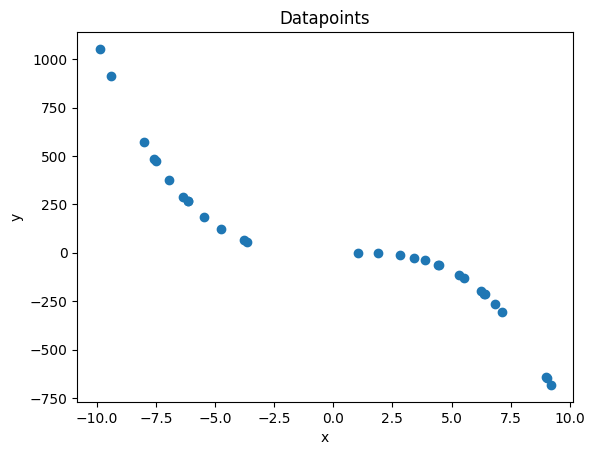

In [ ]:
key = random.PRNGKey(0) #Initialize key
data_key, gp_key = random.split(key) #Split key for data and genetic programming
x = random.uniform(data_key, shape=(30,), minval=-10, maxval = 10) #Inputs
y = -x**3 + x**2 + x #Targets

plt.scatter(x,y)
plt.title("Datapoints")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Next, we can define the hyperparameters of genetic programming in terms of the number of generations (how many iterations of evolution) and the population size (how many solutions to sample at a generation). Furthermore, we have to define a fitness function, for which we can use the predefined `SymbolicRegressionFitnessFunction`, and the genetic programming strategy itself. Finally, run `strategy.fit()` to optimize the function with genetic programming.

In [ ]:
#Define hyperparameters
population_size = 500
num_generations = 10
fitness_function = SymbolicRegressionFitnessFunction()

#Initialize genetic programming strategy
strategy = GeneticProgramming(num_generations, population_size, fitness_function, device_type=backend)

#Fit the strategy on the data. With verbose, we can print the intermediate solutions.
strategy.fit(gp_key, (x[:,None], y), verbose = True)

Input data should be formatted as: ['x0'].
Compiling code for evaluation and evolution...
Finished compilation in 32.72 seconds
In generation 1
Complexity: 0.0, fitness: 159201.078125, equation: 2.82
Complexity: 1.0, fitness: 151356.828125, equation: -1.8*x0
Complexity: 2.0, fitness: 149990.28125, equation: x0**2 - x0
Complexity: 3.0, fitness: 1428.234375, equation: x0**2*(0.222 - x0)
Complexity: 7.0, fitness: 1375.97412109375, equation: x0**2*(0.242 - x0) + 0.843*x0 - 0.737
In generation 2
Complexity: 0.0, fitness: 159161.046875, equation: 3.24
Complexity: 1.0, fitness: 151356.828125, equation: -1.8*x0
Complexity: 2.0, fitness: 140768.46875, equation: -4.25*x0
Complexity: 3.0, fitness: 40.39661407470703, equation: x0*(-x0**2 + x0)
In generation 3
Complexity: 0.0, fitness: 159161.046875, equation: 3.24
Complexity: 1.0, fitness: 151356.828125, equation: -1.8*x0
Complexity: 2.0, fitness: 140768.46875, equation: -4.25*x0
Complexity: 3.0, fitness: 40.39661407470703, equation: x0*(-x0**2 + 

# Control policies

However, Kozax can also be used for other tasks than fitting to data. An example of such an application is learning a symbolic control policy. Kozax also implements a fitness function that is compatible with `gymnax`.

In [ ]:
import gymnax
from kozax.fitness_functions.Gymnax_fitness_function import GymFitnessFunction

key = random.PRNGKey(0)
data_key, gp_key = random.split(key, 2)

# The data comprises keys need to initialize the batch of environments.
batch_size = 4
batch_keys = random.split(data_key, batch_size)

fitness_function = GymFitnessFunction("Pendulum-v1")

population_size = 500
num_generations = 25

#Define operators and variables
operator_list = [
    {"string": "+", "fn": lambda x, y: jnp.add(x, y), "arity": 2, "prob": 0.4},
    {"string": "*", "fn": lambda x, y: jnp.multiply(x, y), "arity": 2, "prob": 0.4},
    ]

variable_list = [[f"y{i}" for i in range(fitness_function.env.observation_space(fitness_function.env_params).shape[0])]]
strategy = GeneticProgramming(num_generations, population_size, fitness_function, operator_list=operator_list, variable_list=variable_list, device_type=backend)

strategy.fit(gp_key, batch_keys, verbose=5)

Input data should be formatted as: ['y0', 'y1', 'y2'].
Compiling code for evaluation and evolution...
Finished compilation in 31.00 seconds
In generation 1
Complexity: 0.0, fitness: 1330.3568115234375, equation: 0.135
Complexity: 1.0, fitness: 1153.668212890625, equation: y0 - 2.06
Complexity: 3.0, fitness: 755.5645751953125, equation: -1.59*y0*(y2 - 0.251)
Complexity: 4.0, fitness: 739.7608642578125, equation: -2.52*y0*y2 + y1*y2
In generation 6
Complexity: 0.0, fitness: 1223.32373046875, equation: -1.72
Complexity: 1.0, fitness: 1153.668212890625, equation: y0 - 2.06
Complexity: 2.0, fitness: 637.162353515625, equation: -2.52*y0*y2
Complexity: 3.0, fitness: 538.20458984375, equation: -3.18*y0*y2
Complexity: 4.0, fitness: 411.2896728515625, equation: -2.35*y0*(y1 + 2*y2)
Complexity: 7.0, fitness: 309.5693664550781, equation: -2.52*y0*y2 + y1*(y0*y1 - 4.61)
In generation 11
Complexity: 0.0, fitness: 1223.32373046875, equation: -1.72
Complexity: 1.0, fitness: 1153.668212890625, equation

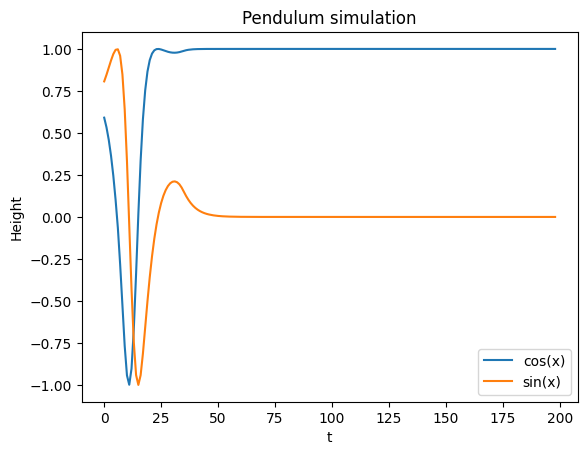

In [ ]:
#Visualize the evolved policy
env, env_params = gymnax.make('Pendulum-v1')
key = random.PRNGKey(2)
obs, env_state = env.reset(key)
all_obs = []
treward = []
actions = []

pareto_fitness, pareto_front = strategy.pareto_front
best_solution = pareto_front[jnp.argmin(pareto_fitness)]

done = False

sin = jnp.sin
cos = jnp.cos

T=199
for t in range(T):

    y0, y1, y2 = obs
    action = strategy.tree_evaluator(best_solution, obs)
    obs, env_state, reward, done, _ = env.step(
                random.fold_in(key, t), env_state, action, env_params
            )

    all_obs.append(obs)
    treward.append(reward)
    actions.append(action)

all_obs = jnp.array(all_obs)
plt.plot(all_obs[:,0], label='cos(x)')
plt.plot(all_obs[:,1], label='sin(x)')
plt.title("Pendulum simulation")
plt.xlabel("t")
plt.ylabel("Height")
plt.legend()

# Defining your own fitness function

You can also define your own fitness function. There are a few requirements for the fitness function to make it compatible with Kozax:

- The class should have a `__call__` method, which receives the `candidate`, `data` and `tree_evaluator`.
- A tree can be solved by running `tree_evaluator` with the `candidate` and data as inputs.
- The `__call__` method should return a scalar if one objective is required, or an array of length `n_objectives`.
- The `__call__` method should be fully vectorizable.

In [ ]:
from kozax.fitness_functions.base_fitness_function import BaseFitnessFunction

# Simple fitness function for symbolic regression
class SymbolicRegressionFitnessFunction(BaseFitnessFunction):

    def __init__(self):
        self.n_objectives = 1

    def __call__(self, candidate, data, tree_evaluator) -> float:
        x, y = data
        pred = jax.vmap(tree_evaluator, in_axes=[None, 0])(candidate, x)
        return jnp.mean(jnp.square(pred[:,0] - y))

# Multi-objective fitness function with regularization on the prediction magnitude
class MOOFitnessFunction(BaseFitnessFunction):

    def __init__(self):
        self.n_objectives = 2

    def __call__(self, candidate, data, tree_evaluator) -> float:
        x, y = data
        pred = jax.vmap(tree_evaluator, in_axes=[None, 0])(candidate, x)
        mse = jnp.mean(jnp.square(pred[:,0] - y))
        regularization = jnp.mean(jnp.square(pred[:,0]))
        return jnp.array([mse, regularization])

In the fitness function there is much flexibility, such as including prior knowledge, evaluating individual trees on different parts of the data, adding regularization etc. In the next tutorial we will show how the fitness function can be extended to learn learning rules for many-agent-systems.

# Kozax-ABMax interface

We can largely reuse the ABMax functionality inside the Kozax fitness function. The candidate function will be evaluated with `tree_evaluator`, which has to be called where we want to compute the utility of the agents. Therefore, we overwrite `set_utilities` and compute the utility of an agent in its current position and the utility of the candidate positions. The computation of the agent utilities can be vectorized with `vmap`, and with a nested `vmap` the utility of the candidate positions are computed efficiently for all agents. We also have to create a method for `step_world` in the fitness function to call the new version of `set_utilities`.

In [ ]:
class FitnessFunction(BaseFitnessFunction):
    def __init__(self, schelling_worlds: SchellingWorld) -> None:
        self.schelling_worlds = schelling_worlds

    def __call__(self, candidate, data, tree_evaluator) -> float:
        fitness = self.get_fitness(candidate, tree_evaluator)
        return jnp.mean(fitness)

    def get_fitness(self, candidate, tree_evaluator):
        utility_f = candidate

        def set_utilities(agent_set, candidate_ids):
            #winning function is u = -f_move_self/f_color_self
            f_color_self = agent_set.agents.state.content['f_color_self'] # shape: (NUM_AGENTS, 1)
            f_empty_self = agent_set.agents.state.content['f_empty_self'] # shape: (NUM_AGENTS, 1)
            f_move_self = agent_set.agents.state.content['f_move_self'] # shape: (NUM_AGENTS, 1)
            f_dist_self = jnp.zeros_like(f_move_self) # shape: (NUM_AGENTS, 1)
            f_age_self = agent_set.agents.state.content['f_age_self'] # shape: (NUM_AGENTS, 1)

            self_features = jnp.concatenate([f_move_self, f_color_self, f_empty_self, f_dist_self, f_age_self], axis=1)

            f_color_candidates = agent_set.agents.state.content['f_color_candidates'] # shape: (NUM_AGENTS, NUM_INACTIVE_AGENTS)
            f_empty_candidates = agent_set.agents.state.content['f_empty_self'][candidate_ids] # shape: (NUM_INACTIVE_AGENTS, 1)
            f_move_candidates = 1 - f_move_self # shape: (NUM_AGENTS, 1)
            f_dist_candidates = agent_set.agents.state.content['f_dist_candidates'] # shape: (NUM_AGENTS, NUM_INACTIVE_AGENTS)
            f_age_candidates = agent_set.agents.state.content['f_age_self'][candidate_ids] # shape: (NUM_INACTIVE_AGENTS, 1)

            candidate_features = jnp.stack([ jnp.broadcast_to(1.0 - f_move_self, (NUM_AGENTS, NUM_INACTIVE_AGENTS)),
                                            f_color_candidates,
                                           jnp.broadcast_to(f_empty_candidates.reshape(-1)[None, :],(NUM_AGENTS, NUM_INACTIVE_AGENTS)),
                                            f_dist_candidates,
                                            jnp.broadcast_to(f_age_candidates.reshape(-1)[None, :],(NUM_AGENTS, NUM_INACTIVE_AGENTS)),
                                            ], axis=-1,) # shape: (NUM_AGENTS, NUM_INACTIVE_AGENTS, 5)


            utility_self = jax.vmap(tree_evaluator, in_axes=(None, 0))(utility_f, self_features).reshape(NUM_AGENTS, 1)# shape: (NUM_AGENTS,1)

            utility_candidates = jax.vmap(jax.vmap(tree_evaluator, in_axes=(None, 0)), in_axes=(None, 0))(utility_f, candidate_features).squeeze(axis=-1) # shape: (NUM_AGENTS, NUM_INACTIVE_AGENTS)

            agents = jax.vmap(SchellingAgent.set_utility)(agent_set.agents, Params(content={'utility_self': utility_self, 'utility_candidates': utility_candidates}))
            agent_set = agent_set.replace(agents=agents)

            return agent_set

        def step_world(schelling_world, _t):
            """
            1. Identify inactive candidate cells
            2. Calculate global max_age
            3. vmap(step_neighborhood)
                - read start-of-tick color/age
                - calculate home/location factors
                - roll movement history
                - consume and reset move_flag
                - increment age once
            4. vmap(step_candidates)
                - calculate candidate-specific factors
            5. set_utilities() once
                - home utilities
                - candidate utilities
            6. Construct positive utility-gain matrix
            7. Maximum-weight matching
            8. Activate destinations and inactivate origins
            9. End tick
            """
            agent_set = schelling_world.schelling_set
            max_age = jnp.max(schelling_world.schelling_set.agents.age) # get the maximum age of the agents in the environment

            step_neighborhood_params = Params(content={'agents': agent_set.agents, 'max_age': max_age})
            agent_set = jit_step_agents(step_func = SchellingAgent.step_neighborhood, step_params=step_neighborhood_params, input=None, set=agent_set)

            select_inactive_agents_func = lambda agent, _ : agent.active_state == 0

            num_inactive, inactive_ids = jit_select_agents(select_func = select_inactive_agents_func, select_params = None, set = agent_set)
            candidate_ids = inactive_ids[:NUM_INACTIVE_AGENTS] # take only the first NUM_INACTIVE_AGENTS inactive agents, in case there are more than NUM_INACTIVE_AGENTS inactive agents

            step_candidates_params = Params(content={'agents': agent_set.agents,
                                                    'candidate_ids': candidate_ids,
                                                    'candidate_Xs': agent_set.agents.params.content['X'][candidate_ids],
                                                    'candidate_Ys': agent_set.agents.params.content['Y'][candidate_ids]})
            agent_set = jit_step_agents(step_func = SchellingAgent.step_candidates, step_params=step_candidates_params, input=None, set=agent_set)

            #asign utilities to all agents
            agent_set = set_utilities(agent_set, candidate_ids)
            moves, key = SchellingWorld.get_moves(agent_set, schelling_world.key)
            # moves is a (NUM_AGENTS, NUM_INACTIVE_AGENTS) matrix where moves[i,j] = 1 if agent i wants to move to candidate j, and 0 otherwise

            # move agents by activating the destination agents and inactivating the origin agents
            #1. activation of destination agents
            candidate_gets_agent = jnp.any(moves == 1, axis=0) # candidate_gets_agent[j] = 1 if candidate j gets an agent, and 0 otherwise
            source_for_candidate = jnp.argmax(moves, axis=0) # source_for_candidate[j] = i if agent i wants to move to candidate j, and 0 otherwise
            candidate_parents = jnp.where(candidate_gets_agent, source_for_candidate, candidate_ids) # candidate_parents[j] = i if candidate j gets an agent from source i, and 0 otherwise
            parent_ids = jnp.arange(NUM_AGENTS)
            parent_ids = parent_ids.at[candidate_ids].set(candidate_parents)
            activate_params = Params(content={'agents': agent_set.agents, 'set_indx':parent_ids})
            agent_set = jit_set_agents_pair(set_func = SchellingAgent.activate_agent, set_params=activate_params, set = agent_set)

            #2. inactivation of origin agents
            inactivate_mask = jnp.any(moves == 1, axis=1) # if inactive_mask[i] ==1, the the agent has moved and should be inactivated.
            mask_params = Params(content={'set_mask':inactivate_mask})
            agent_set = jit_set_agents_mask(set_func = SchellingAgent.inactivate_agent, set_params=None, mask_params = mask_params, num_agents=-1, set = agent_set)

            neighborhood_proportions = SchellingWorld.get_neighborhood_proportions(agent_set)

            return schelling_world.replace(schelling_set=agent_set, neighborhood_proportions=neighborhood_proportions, key=key), neighborhood_proportions

        schelling_worlds = jax.vmap(SchellingWorld.reset_world)(self.schelling_worlds)
        self.schelling_worlds, proportions_by_scenario = jax.vmap(lambda schelling_world: jax.lax.scan(step_world, schelling_world, None, length=EPISODE_LENGTH))(schelling_worlds)


        final_window = proportions_by_scenario[:, -FITNESS_WINDOW:, :3] # (NUM_SCENARIOS, FITNESS_WINDOW, 3)

        retained_area = jnp.sum(final_window, axis=-1) # (NUM_SCENARIOS, FITNESS_WINDOW)

        c_index = jnp.where(retained_area > 0.0, jnp.min(final_window, axis=-1) / retained_area, 0.0)

        return -jnp.mean(c_index)

Now we can initialize the schelling worlds (multiple scenarios) and the fitness function. Furthermore we define more operators and the relevant variables. To learn symbolic functions with only the variables and without constants, we can set `constant_sd` to 0.

In [ ]:
def main_gp():
    key, *schelling_world_keys = random.split(KEY, NUM_SCENARIOS + 1)
    schelling_world_keys = jnp.array(schelling_world_keys).reshape(NUM_SCENARIOS, 2)
    schelling_worlds = jax.vmap(SchellingWorld.create_world, in_axes=(None, 0))(None, schelling_world_keys)

    fitness_function = FitnessFunction(schelling_worlds)

    #Define hyperparameters
    population_size = POP_SIZE
    num_generations = NUM_GENERATIONS

    variable_list = [["f_move", "f_color", "f_empty", "f_dist", "f_age"]]

    operator_list = [{"string": "+", "fn": lambda x, y: jnp.add(x, y), "arity": 2, "prob": 0.1},
                        {"string": "-", "fn": lambda x, y: jnp.subtract(x, y), "arity": 2, "prob": 0.1},
                        {"string": "*", "fn": lambda x, y: jnp.multiply(x, y), "arity": 2, "prob": 0.1},
                        {"string": "/", "fn": lambda x, y: jnp.divide(x, y + 1e-6), "arity": 2, "prob": 0.1}
                        ]

    layer_sizes = jnp.array([1])

    #Initialize genetic programming strategy
    strategy = GeneticProgramming(num_generations, population_size, fitness_function, variable_list=variable_list, layer_sizes=layer_sizes,
                                operator_list = operator_list,
                                                max_init_depth = 4,
                                                max_nodes = 10,
                                                constant_sd = 0,
                                                device_type='gpu'
                                            )

    strategy.fit(key, (), verbose=5)

In [ ]:
main_gp()

Input data should be formatted as: ['f_move', 'f_color', 'f_empty', 'f_dist', 'f_age'].
Compiling code for evaluation and evolution...
Finished compilation in 68.63 seconds
In generation 1
Complexity: 1.0, fitness: -0.006983350496739149, equation: f_age + f_color
Complexity: 2.0, fitness: -0.07468046993017197, equation: (f_age + f_color)/f_empty
Complexity: 4.0, fitness: -0.18139317631721497, equation: f_age**2*f_color/f_move**2
In generation 6
Complexity: 0.0, fitness: -0.0, equation: f_color
Complexity: 1.0, fitness: -0.1990247368812561, equation: f_color - f_dist
Complexity: 2.0, fitness: -0.24331551790237427, equation: f_age + f_color - f_dist
Complexity: 4.0, fitness: -0.2556818127632141, equation: f_color*f_dist*f_empty + f_color - f_dist
In generation 11
Complexity: 0.0, fitness: -0.0007062874501571059, equation: f_dist
Complexity: 1.0, fitness: -0.1990247368812561, equation: f_color - f_dist
Complexity: 2.0, fitness: -0.24331551790237427, equation: f_age + f_color - f_dist
Comp